# 09 — Forecast profiles at observed ice pellet and freezing rain reports, compared with RAP

Two figures showing how the forecast models' temperature and dew point profiles differ from the RAP analysis at mPING reports of **ice pellets** and **freezing rain**.

- **Figure 1 – composite skew-T:** median temperature (solid) and dew point (dashed), RAP (thick grey) and each model, at forecast days 1 and 7.
- **Figure 2 – temperature difference from RAP:** median and interquartile range of forecast − RAP, at forecast days 1, 3 and 7.

**Sample:** QC'd mPING reports at 00/06/12/18 UTC, 1 Dec 2021 – 31 Mar 2022, observed class by the modal rule (as notebooks 01–07). Profiles are on the common 0–5 km AGL grid at 250 m spacing; RAP profiles come from the QC'd parquet, forecast profiles (`T_HEIGHT`, `DPT_HEIGHT`) from each model's output at the nearest grid point. Only reports where every model has a complete profile are used, so the models are compared on identical cases.

**Outputs** (in `FIG`): `composite_skewt_mixedphase.pdf`, `composite_bias_T_mixedphase.pdf`.

> Medians are taken level by level, so a composite is not a single real sounding and smooths features whose height varies between cases (e.g. the warm nose). RAP is an analysis, not truth: these are differences from a common reference.

## 1. Imports

In [1]:
from pathlib import Path
import glob, re
import numpy as np
import pandas as pd
import xarray as xr
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

## 2. Configuration

**Copy from your notebook 05/07:** `MODEL_DIRS`, `FILE_GLOBS`.

- `T_VAR`, `TD_VAR`: forecast temperature and dew point on heights (`T_HEIGHT`, `DPT_HEIGHT`).
- `RAP_T_PATTERN`, `RAP_TD_PATTERNS`: RAP columns in the parquet. Section 4 prints what is found; set `RAP_TD_PATTERNS` if the dew point columns use another name.
- `DAYS`: forecast days to composite.

In [2]:
# ---------- paths and sample (same as notebooks 01–07) ----------
OBS_RULE = "modal"
_RULE_SUFFIX = "" if OBS_RULE == "consensus" else f"_{OBS_RULE}"
MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"
AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
OUT = AI_BASE / f"verification_multimodel{_RULE_SUFFIX}" / "profile_composites"
FIG = Path("/glade/work/sakor/AI_NWP") / f"figures{_RULE_SUFFIX}"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

START, END = pd.Timestamp("2021-12-01 00:00"), pd.Timestamp("2022-03-31 18:00")
SYNOPTIC_HOURS = [0, 6, 12, 18]
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 24.0, 50.0, -125.0, -66.0
PTYPE_COLS = {"sn_percent": "Snow", "ra_percent": "Rain",
              "pl_percent": "Ice Pellet", "fzra_percent": "Freezing Rain"}
TIE_PRIORITY = ["fzra_percent", "pl_percent", "sn_percent", "ra_percent"]

      
# ---------- forecasts (copy from notebook 05/07) ----------
MODELS = ["Aurora", "GraphCast", "WXFormer", "FuXi", "Pangu-Weather", "GFS"]
MODEL_DIRS = {
    "Aurora": AI_BASE / "au_ptype",
    "GraphCast": AI_BASE / "gc_ptype",       
    "WXFormer": AI_BASE / "wx_ptype",        
    "FuXi": AI_BASE / "fuxi_ptype",                 
    "Pangu-Weather": AI_BASE / "pw_ptype",       
    "GFS": AI_BASE / "gfs",                  
}
FILE_GLOBS = [
    "{init:%Y-%m-%dT%H}Z/*_{lead:03d}.nc",
    "{init:%Y-%m-%dT%H}Z/*_{lead}.nc",
    "{init:%Y%m%d%H}/*_{lead}.nc",
    "{init:%Y%m%d%H}/*_{lead:03d}.nc",
]
T_VAR, TD_VAR, EDNN_VAR = "T_HEIGHT", "DPT_HEIGHT", "ML_ptype"
DAYS = [1, 3, 7]
MAX_POINT_KM = 30.0
COMMON_VALID = True

# ---------- RAP reference columns ----------
RAP_T_PATTERN = re.compile(r"^TEMP_C_(\d+)_m$")
RAP_TD_PATTERNS = [re.compile(p) for p in (r"^T_DEWPOINT_C_(\d+)_m$", r"^DEWPOINT_C_(\d+)_m$", r"^DPT_C_(\d+)_m$",
                                            r"^TD_C_(\d+)_m$", r"^DEW_C_(\d+)_m$")]

# ---------- analysis ----------
CLASSES = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
CLASS_CODE = {"Rain": 0, "Snow": 1, "Ice Pellet": 2, "Freezing Rain": 3}
SPLIT_BY_OUTCOME = True                  # EDNN hit vs miss for mixed-phase classes
LAYERS = {"0-1 km": (0, 1000), "1-3 km": (1000, 3000)}
MIN_N = 30                               # do not plot composites with fewer reports

MODEL_COLORS = {"Aurora": "#0072B2", "GraphCast": "#E69F00", "WXFormer": "#009E73",
                "FuXi": "#CC79A7", "Pangu-Weather": "#D55E00", "GFS": "#000000"}
VAR_LABELS = {"T": "Air temperature, forecast − RAP (°C)",
              "Td": "Dew point, forecast − RAP (°C)",
              "DD": "Dew-point depression T − Td, forecast − RAP (°C)"}
plt.rcParams.update({"font.family": "sans-serif", "font.size": 8,
                     "pdf.fonttype": 42, "ps.fonttype": 42})

## 3. Helpers

In [3]:
def init_and_lead(valid, day):
    # notebook-01 rule: 00Z inits; day n covers leads 24(n-1)+6 ... 24n h
    init = (valid - pd.Timedelta(hours=1)).floor("D") - pd.Timedelta(days=day - 1)
    lead = int((valid - init) / pd.Timedelta(hours=1))
    assert 24 * (day - 1) + 6 <= lead <= 24 * day, (valid, day, init, lead)
    return init, lead

def forecast_file(model, init, lead):
    for pat in FILE_GLOBS:
        hits = sorted(glob.glob(str(MODEL_DIRS[model] / pat.format(init=init, lead=lead))))
        if len(hits) == 1:
            return Path(hits[0])
        if len(hits) > 1:
            raise RuntimeError(f"{model}: several files for init {init}, lead {lead}")
    return None

def _latlon_names(ds):
    lat = next(n for n in ("latitude", "lat", "XLAT", "gridlat_0") if n in ds.variables)
    lon = next(n for n in ("longitude", "lon", "XLONG", "gridlon_0") if n in ds.variables)
    return lat, lon

def _xyz(lat, lon):
    la, lo = np.radians(lat), np.radians(lon)
    return np.c_[np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]

def _chord_to_km(d):
    return 2 * 6371.0 * np.arcsin(np.clip(d / 2, 0, 1))

_grid_cache = {}
def nearest_index(ds, lat_p, lon_p):
    lat_n, lon_n = _latlon_names(ds)
    lat, lon = ds[lat_n].values, ds[lon_n].values
    one_d = lat.ndim == 1 and lon.ndim == 1
    key = (lat.shape, lon.shape, float(lat.flat[0]), float(lon.flat[0]))
    if key not in _grid_cache:
        lon2, lat2 = np.meshgrid(lon, lat) if one_d else (lon, lat)
        lon2 = ((lon2 + 180.0) % 360.0) - 180.0
        _grid_cache[key] = (cKDTree(_xyz(lat2.ravel(), lon2.ravel())), lat2.shape)
    tree, shape = _grid_cache[key]
    d, i = tree.query(_xyz(lat_p, lon_p))
    iy, ix = np.unravel_index(i, shape)
    return iy, ix, _chord_to_km(d), lat_n, lon_n, one_d

def sample(ds, var, iy, ix, lat_n, lon_n, one_d):
    da = ds[var].squeeze(drop=True)
    if one_d:
        ydim, xdim = lat_n, lon_n
    else:
        ydim, xdim = ds[lat_n].dims
    v = da.isel({ydim: xr.DataArray(iy, dims="pt"), xdim: xr.DataArray(ix, dims="pt")})
    return v.transpose("pt", ...).values.astype(float)

def height_coord(ds, var):
    da = ds[var].squeeze(drop=True)
    lat_n, lon_n = _latlon_names(ds)
    hdim = [d for d in da.dims if d not in (lat_n, lon_n) and d not in ds[lat_n].dims]
    if len(hdim) != 1:
        raise ValueError(f"{var}: cannot identify the height dimension in {da.dims}")
    return np.asarray(ds[hdim[0]].values, float)

def to_celsius(a):
    return a - 273.15 if np.nanmedian(a) > 200 else a

## 4. mPING reports and RAP profiles

Observed class by the same modal rule as notebooks 01–07. RAP temperature and dew point profiles at each report come from the QC'd parquet; the cell prints the columns it found.

In [4]:
schema = pq.read_schema(MPING_PATH).names
def find_cols(patterns):
    for pat in patterns:
        cols = [c for c in schema if pat.match(c)]
        if cols:
            cols = sorted(cols, key=lambda c: int(pat.match(c).group(1)))
            return cols, np.array([int(pat.match(c).group(1)) for c in cols], float)
    return [], np.array([])

MAX_HEIGHT = 5000.0                                # forecast / EDNN profiles end at 5 km
rap_t_cols, RAP_H = find_cols([RAP_T_PATTERN])
rap_td_cols, RAP_H_TD = find_cols(RAP_TD_PATTERNS)
rap_t_cols = [c for c, h in zip(rap_t_cols, RAP_H) if h <= MAX_HEIGHT]
rap_td_cols = [c for c, h in zip(rap_td_cols, RAP_H_TD) if h <= MAX_HEIGHT]
RAP_H, RAP_H_TD = RAP_H[RAP_H <= MAX_HEIGHT], RAP_H_TD[RAP_H_TD <= MAX_HEIGHT]
print(f"RAP temperature columns: {len(rap_t_cols)} ({RAP_H.min():.0f}–{RAP_H.max():.0f} m)")
if not rap_td_cols:
    cand = [c for c in schema if re.search(r"dew|dpt|td", c, re.I)]
    raise KeyError(f"No RAP dew point columns matched RAP_TD_PATTERNS. Candidates: {cand[:20]}")
print(f"RAP dew point columns:   {len(rap_td_cols)} ({RAP_H_TD.min():.0f}–{RAP_H_TD.max():.0f} m), e.g. {rap_td_cols[0]}")
assert np.array_equal(RAP_H, RAP_H_TD), "RAP T and Td columns are on different heights"
HEIGHTS = RAP_H                                    # composites are on the RAP height grid

obs = pd.read_parquet(MPING_PATH, columns=["datetime", "lat", "lon"] + TIE_PRIORITY + rap_t_cols + rap_td_cols)
obs["datetime"] = pd.to_datetime(obs["datetime"])
obs = obs[obs.datetime.between(START, END) & obs.datetime.dt.hour.isin(SYNOPTIC_HOURS)
          & (obs.datetime.dt.minute == 0)
          & obs.lat.between(LAT_MIN, LAT_MAX) & obs.lon.between(LON_MIN, LON_MAX)]
raw = obs[TIE_PRIORITY].astype(float).fillna(0.0)
if raw.to_numpy().max() <= 1.0:
    raw = raw * 100.0
obs = obs.assign(obs_class=raw.round(6).idxmax(axis=1).map(PTYPE_COLS))[raw.max(axis=1).values > 0]
obs = obs.reset_index(drop=True)
obs["report_id"] = np.arange(len(obs))

RAP_T = to_celsius(obs[rap_t_cols].to_numpy(float))
RAP_TD = to_celsius(obs[rap_td_cols].to_numpy(float))
print(f"\nReports: {len(obs):,} at {obs.datetime.nunique()} valid times")
display(obs.obs_class.value_counts().reindex(CLASSES).to_frame("reports"))

RAP temperature columns: 21 (0–5000 m)
RAP dew point columns:   21 (0–5000 m), e.g. T_DEWPOINT_C_0_m

Reports: 30,856 at 475 valid times


,reports
obs_class,
Rain,11932
Snow,16116
Ice Pellet,1772
Freezing Rain,1036


## 5. Extract forecast profiles at the reports (cached)

For each model and forecast day, every valid time is matched to the forecast with the right initialization and lead, and T, Td and the EDNN class are read at the nearest native grid point. Profiles are interpolated linearly to the RAP heights if the grids differ. Missing files and reports farther than `MAX_POINT_KM` from a grid point are left as NaN.

In [5]:
def extract(model, day):
    cache = OUT / f"profiles_{model.lower().replace('-', '')}_day{day}.nc"
    if cache.exists():
        c = xr.open_dataset(cache).load()
        n_ok = int(np.isfinite(c["T"].values).all(1).sum())
        if np.array_equal(c["height"].values, HEIGHTS) and c.sizes["report"] == len(obs) and n_ok > 0:
            return c
        print(f"  {model} day {day}: cache stale or empty ({n_ok} valid) -> rebuilding")
        c.close(); cache.unlink()
    n, nz = len(obs), HEIGHTS.size
    T = np.full((n, nz), np.nan); TD = np.full((n, nz), np.nan); cls = np.full(n, np.nan)
    missing = 0
    for vt, g in obs.groupby("datetime"):
        init, lead = init_and_lead(vt, day)
        f = forecast_file(model, init, lead)
        if f is None:
            missing += 1
            continue
        with xr.open_dataset(f, decode_timedelta=False) as ds:
            iy, ix, dist, lat_n, lon_n, one_d = nearest_index(ds, g.lat.to_numpy(), g.lon.to_numpy())
            ok = dist <= MAX_POINT_KM
            h = height_coord(ds, T_VAR)
            t = to_celsius(sample(ds, T_VAR, iy, ix, lat_n, lon_n, one_d))
            td = to_celsius(sample(ds, TD_VAR, iy, ix, lat_n, lon_n, one_d))
            c = sample(ds, EDNN_VAR, iy, ix, lat_n, lon_n, one_d).ravel()
        if not np.array_equal(h, HEIGHTS):
            t = np.array([np.interp(HEIGHTS, h, row, left=np.nan, right=np.nan) for row in t])
            td = np.array([np.interp(HEIGHTS, h, row, left=np.nan, right=np.nan) for row in td])
        idx = g.index.to_numpy()
        T[idx[ok]], TD[idx[ok]] = t[ok], td[ok]
        cls[idx[ok]] = np.where(np.isin(c[ok], [0, 1, 2, 3]), c[ok], np.nan)
    out = xr.Dataset({"T": (("report", "height"), T), "Td": (("report", "height"), TD),
                      "ednn_class": ("report", cls)},
                     coords={"report": obs.report_id.to_numpy(), "height": HEIGHTS})
    out.attrs.update(model=model, day=day, missing_valid_times=missing)
    n_ok = int(np.isfinite(T).all(1).sum())
    print(f"  {model:14s} day {day}: {n_ok:6d} complete profiles, "
          f"{missing} of {obs.datetime.nunique()} valid times without a file")
    if n_ok > 0:
        out.to_netcdf(cache)
    else:
        print(f"    -> nothing extracted for {model}; check MODEL_DIRS / FILE_GLOBS (not cached)")
    return out

prof = {(m, d): extract(m, d) for d in DAYS for m in MODELS}

/glade/work/sakor/conda-envs/mlguess/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


  GFS            day 1:      0 complete profiles, 475 of 475 valid times without a file
    -> nothing extracted for GFS; check MODEL_DIRS / FILE_GLOBS (not cached)
  GFS            day 3:      0 complete profiles, 475 of 475 valid times without a file
    -> nothing extracted for GFS; check MODEL_DIRS / FILE_GLOBS (not cached)
  GFS            day 7:      0 complete profiles, 475 of 475 valid times without a file
    -> nothing extracted for GFS; check MODEL_DIRS / FILE_GLOBS (not cached)


## 6. Differences from RAP and the common sample

Differences are forecast − RAP at every height. With `COMMON_VALID = True`, a report is kept for a forecast day only if every model has a complete T and Td profile there (and RAP does too).

In [6]:
rap_ok = np.isfinite(RAP_T).all(1) & np.isfinite(RAP_TD).all(1)
diff, keep = {}, {}
USED = {}
for d in DAYS:
    ok_all = rap_ok.copy()
    USED[d] = []
    for m in MODELS:
        p = prof[(m, d)]
        ok_m = np.isfinite(p["T"].values).all(1) & np.isfinite(p["Td"].values).all(1)
        keep[(m, d)] = ok_m & rap_ok
        print(f"day {d}  {m:14s} complete T and Td profiles: {int(keep[(m, d)].sum()):6d}")
        if keep[(m, d)].sum() == 0:
            print(f"    -> {m} has no data at day {d}; left out of the comparison")
            continue
        USED[d].append(m)
        ok_all &= ok_m
    for m in USED[d]:
        p = prof[(m, d)]
        sel = ok_all if COMMON_VALID else keep[(m, d)]
        dT = p["T"].values - RAP_T
        dTd = p["Td"].values - RAP_TD
        dDD = (p["T"].values - p["Td"].values) - (RAP_T - RAP_TD)
        diff[(m, d)] = dict(T=dT[sel], Td=dTd[sel], DD=dDD[sel],
                            cls=obs.obs_class.to_numpy()[sel],
                            hit=(p["ednn_class"].values[sel] == obs.obs_class.map(CLASS_CODE).to_numpy()[sel]))
    print(f"Day {d}: {int(ok_all.sum()):,} reports with complete profiles from all models")

n_tab = pd.DataFrame({(m, d): pd.Series(diff[(m, d)]["cls"]).value_counts().reindex(CLASSES)
                      for (m, d) in diff}).T
n_tab.index.names = ["model", "day"]
display(n_tab.groupby(level="day").first())

day 1  Aurora         complete T and Td profiles:  30830
day 1  GraphCast      complete T and Td profiles:  30678
day 1  WXFormer       complete T and Td profiles:  30684
day 1  FuXi           complete T and Td profiles:  30614
day 1  Pangu-Weather  complete T and Td profiles:  30684
day 1  GFS            complete T and Td profiles:      0
    -> GFS has no data at day 1; left out of the comparison
Day 1: 30,262 reports with complete profiles from all models
day 3  Aurora         complete T and Td profiles:  30836
day 3  GraphCast      complete T and Td profiles:  30746
day 3  WXFormer       complete T and Td profiles:  30820
day 3  FuXi           complete T and Td profiles:  30754
day 3  Pangu-Weather  complete T and Td profiles:  30674
day 3  GFS            complete T and Td profiles:      0
    -> GFS has no data at day 3; left out of the comparison
Day 3: 30,480 reports with complete profiles from all models
day 7  Aurora         complete T and Td profiles:  30844
day 7  GraphCast 

,Rain,Snow,Ice Pellet,Freezing Rain
day,,,,
1,11886,15586,1756,1034
3,11890,15802,1752,1036
7,11800,15318,1712,1020


## 7. Figures

Both figures use the common sample from Section 6 and only observed ice pellets and freezing rain.

In [7]:
# import metpy.plots   # registers the "skewx" projection

# FOCUS = ["Ice Pellet", "Freezing Rain"]
# SKEWT_DAYS = [1, 7]
# BIAS_DAYS = [1, 3, 7]
# SKEW_XLIM, SKEW_YLIM, SKEW_ROT = (-20, 15), (-100, 5100), 30
# RAP_STYLE = dict(color="0.45", lw=3.0, alpha=0.75)

# def common_mask(d):
#     ok = rap_ok.copy()
#     for m in USED[d]:
#         p = prof[(m, d)]
#         ok &= np.isfinite(p["T"].values).all(1) & np.isfinite(p["Td"].values).all(1)
#     return ok

# def model_legend(days):
#     return [plt.Line2D([], [], color=MODEL_COLORS[m], lw=1.4, label=m)
#             for m in MODELS if any(m in USED[d] for d in days)]

# # ---------------- Figure 1: composite skew-T ----------------
# fig = plt.figure(figsize=(8.6, 8.4))
# for r, d in enumerate(SKEWT_DAYS):
#     sel_d = common_mask(d)
#     for c, cls in enumerate(FOCUS):
#         k = r * len(FOCUS) + c
#         ax = fig.add_subplot(len(SKEWT_DAYS), len(FOCUS), k + 1, projection="skewx", rotation=SKEW_ROT)
#         sel = sel_d & (obs.obs_class.to_numpy() == cls)
#         ax.plot(np.median(RAP_T[sel], 0), HEIGHTS, **RAP_STYLE, zorder=2)
#         ax.plot(np.median(RAP_TD[sel], 0), HEIGHTS, ls="--", **RAP_STYLE, zorder=2)
#         for m in USED[d]:
#             p = prof[(m, d)]
#             ax.plot(np.median(p["T"].values[sel], 0), HEIGHTS, color=MODEL_COLORS[m], lw=1.4, zorder=3)
#             ax.plot(np.median(p["Td"].values[sel], 0), HEIGHTS, color=MODEL_COLORS[m], lw=1.0, ls="--", zorder=3)
#         ax.axvline(0, color="k", lw=1.1)
#         ax.set_xticks(np.arange(-40, 41, 5)); ax.grid(alpha=0.4)
#         ax.set_xlim(*SKEW_XLIM); ax.set_ylim(*SKEW_YLIM)
#         ax.set_title(f"({'abcd'[k]}) Observed {cls.lower()}, day {d}", loc="left", fontweight="bold", fontsize=8.5)
#         ax.text(0.98, 0.98, f"n = {sel.sum():,}", transform=ax.transAxes, ha="right", va="top", fontsize=7, color="0.3")
#         ax.set_ylabel("Height AGL (m)" if c == 0 else "")
#         if c > 0:
#             ax.tick_params(labelleft=False)
#         ax.set_xlabel("Temperature (°C)" if r == len(SKEWT_DAYS) - 1 else "")
# handles = [plt.Line2D([], [], **RAP_STYLE, label="RAP")] + model_legend(SKEWT_DAYS) + \
#           [plt.Line2D([], [], color="0.3", lw=1.2, label="Temperature"),
#            plt.Line2D([], [], color="0.3", lw=1.0, ls="--", label="Dew point")]
# fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, fontsize=7.5, bbox_to_anchor=(0.5, -0.02))
# fig.tight_layout(rect=(0, 0.06, 1, 1))
# fig.savefig(FIG / "composite_skewt_mixedphase.pdf", bbox_inches="tight")
# plt.show()

# # ---------------- Figure 2: temperature difference from RAP ----------------
# fig, axes = plt.subplots(len(BIAS_DAYS), len(FOCUS), figsize=(6.0, 2.9 * len(BIAS_DAYS)),
#                          sharex=True, sharey=True, squeeze=False)
# for r, d in enumerate(BIAS_DAYS):
#     for c, cls in enumerate(FOCUS):
#         k = r * len(FOCUS) + c
#         ax = axes[r, c]
#         ax.axvline(0, color="0.5", lw=0.8)
#         n = 0
#         for m in USED[d]:
#             D = diff[(m, d)]
#             sel = D["cls"] == cls
#             if sel.sum() < MIN_N:
#                 continue
#             a = D["T"][sel]
#             ax.fill_betweenx(HEIGHTS, np.percentile(a, 25, 0), np.percentile(a, 75, 0),
#                              color=MODEL_COLORS[m], alpha=0.08, lw=0)
#             ax.plot(np.median(a, 0), HEIGHTS, color=MODEL_COLORS[m], lw=1.4)
#             n = int(sel.sum())
#         ax.set_title(f"({'abcdefgh'[k]}) Observed {cls.lower()}, day {d}", loc="left", fontweight="bold", fontsize=8.5)
#         ax.text(0.98, 0.98, f"n = {n:,}", transform=ax.transAxes, ha="right", va="top", fontsize=7, color="0.3")
#         if c == 0:
#             ax.set_ylabel("Height AGL (m)")
#         ax.grid(alpha=0.3)
# fig.tight_layout(rect=(0, 0.07, 1, 1))
# fig.supxlabel("Air temperature, forecast − RAP (°C)", y=0.045, fontsize=9)
# fig.legend(handles=model_legend(BIAS_DAYS), loc="lower center", ncol=5, frameon=False, fontsize=7.5,
#            bbox_to_anchor=(0.5, -0.01))
# fig.savefig(FIG / "composite_bias_T_mixedphase.pdf", bbox_inches="tight")
# plt.show()

## 8. Figure for Section 4.3: how the models differ

Temperature bias and dew-point-depression bias (forecast − RAP; positive dew-point depression = drier than RAP) at observed ice pellet and freezing rain reports, days 1 and 7. Median lines with interquartile shading; x-axes shared within each quantity. The table below gives the layer means (0–1 km, 1–3 km) quoted in the text, including rain and snow reports.


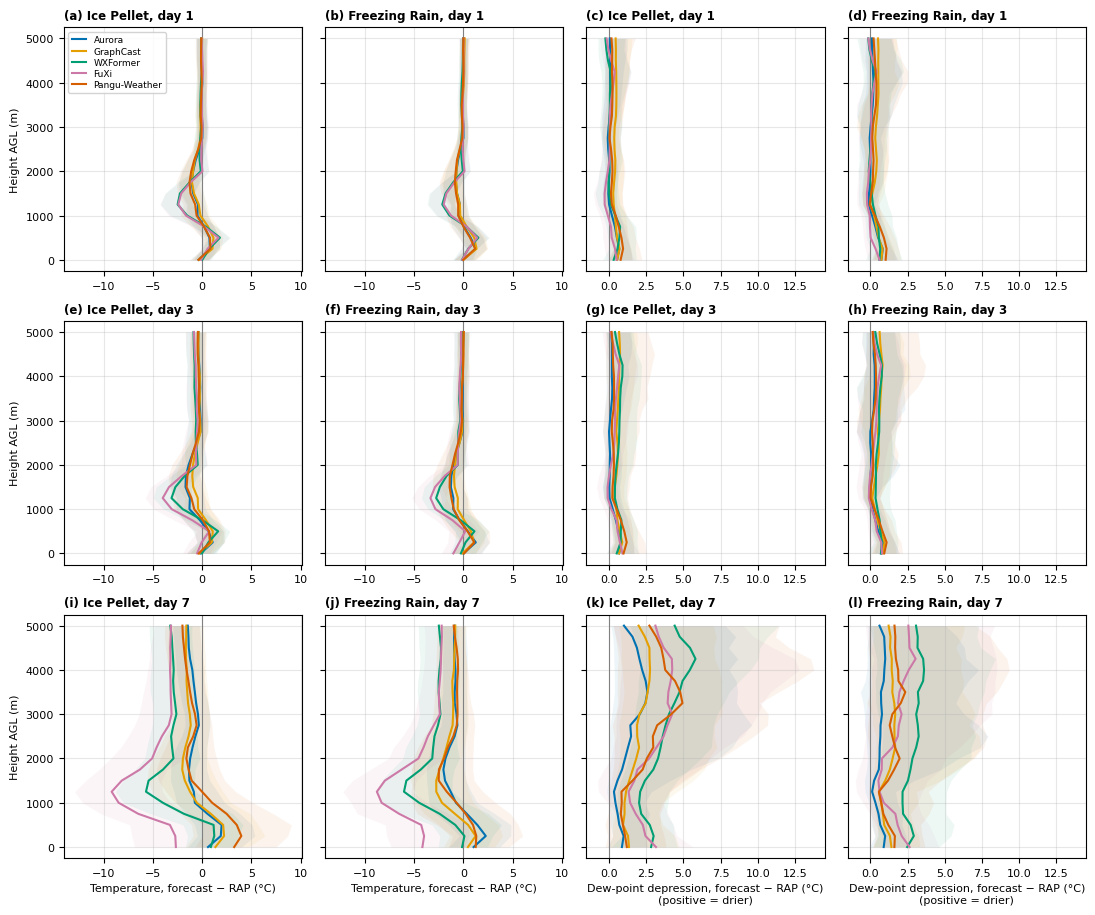

n  T 0-1 km  T 1-3 km  DD 0-1 km  DD 1-3 km
obs_class     day model                                                         
Freezing Rain 1   Aurora          1034      0.30     -0.42       0.51      -0.01
                  FuXi            1034      0.17     -0.66       0.19      -0.06
                  GraphCast       1034      0.49     -0.43       0.56       0.29
                  Pangu-Weather   1034      0.26     -0.52       0.80       0.15
                  WXFormer        1034      0.15     -0.80       0.55       0.08
              3   Aurora          1036      0.06     -0.76       0.53       0.04
                  FuXi            1036     -1.04     -1.48       0.48       0.13
                  GraphCast       1036      0.25     -0.57       0.65       0.41
                  Pangu-Weather   1036      0.04     -0.87       0.74       0.15
                  WXFormer        1036     -0.25     -1.27       0.65       0.46
              7   Aurora          1020      0.86     -1.26       0.69       0.52
                  FuXi            1020     -5.45     -5.43       1.84       1.22
                  GraphCast       1020     -0.17     -1.94       1.05       1.30
                  Pangu-Weather   1020      0.61     -1.47       1.22       1.33
                  WXFormer        1020     -1.55     -3.85       2.50       2.78
Ice Pellet    1   Aurora          1756      0.18     -0.52       0.47       0.00
                  FuXi            1756      0.14     -0.83       0.23      -0.09
                  GraphCast       1756      0.46     -0.53       0.53       0.36
                  Pangu-Weather   1756      0.18     -0.69       0.73       0.18
                  WXFormer        1756      0.28     -0.94       0.55       0.07
              3   Aurora          1752      0.01     -1.00       0.57       0.06
                  FuXi            1752     -0.78     -1.70       0.58       0.17
                  GraphCast       1752      0.35     -0.58       0.67       0.50
                  Pangu-Weather   1752      0.08     -0.93       0.90       0.29
                  WXFormer        1752      0.06     -1.38       0.70       0.55
              7   Aurora          1712      0.85     -0.87       0.71       1.06
                  FuXi            1712     -4.72     -5.82       2.22       2.67
                  GraphCast       1712      1.21     -1.44       1.13       1.64
                  Pangu-Weather   1712      2.85     -0.74       0.97       2.38
                  WXFormer        1712     -0.51     -3.74       2.55       3.08
Rain          1   Aurora         11886      0.02     -0.10       0.10      -0.13
                  FuXi           11886     -0.15     -0.16      -0.07      -0.13
                  GraphCast      11886      0.19     -0.10       0.44       0.20
                  Pangu-Weather  11886     -0.03     -0.15       0.08      -0.12
                  WXFormer       11886     -0.15     -0.17       0.01      -0.12
              3   Aurora         11890     -0.01     -0.16       0.13      -0.02
                  FuXi           11890     -0.51     -0.48       0.12       0.22
                  GraphCast      11890      0.04     -0.12       0.52       0.42
                  Pangu-Weather  11890     -0.13     -0.23       0.19      -0.00
                  WXFormer       11890     -0.41     -0.37       0.26       0.45
              7   Aurora         11800     -0.13     -0.39       0.56       1.14
                  FuXi           11800     -2.32     -2.22       0.50       0.95
                  GraphCast      11800     -0.55     -0.71       0.83       1.07
                  Pangu-Weather  11800     -0.46     -0.60       0.65       0.83
                  WXFormer       11800     -1.31     -1.41       0.76       1.90
Snow          1   Aurora         15586      0.09     -0.22       0.89       0.16
                  FuXi           15586      0.02     -0.24       0.91       0.08
                  GraphCast      15586      0.13     -0.27       0.9

In [8]:
# ================================================================
# Section 4.3 figure: how the models differ
#   rows    = forecast days 1, 3 and 7
#   columns = T bias and dew-point-depression bias, for ice pellets and freezing rain
#   (forecast − RAP; median line, interquartile shading)
# ================================================================
DAYS_43 = [1, 3, 7]
COLS_43 = [("T", "Ice Pellet"), ("T", "Freezing Rain"), ("DD", "Ice Pellet"), ("DD", "Freezing Rain")]
XLAB_43 = {"T": "Temperature, forecast − RAP (°C)",
           "DD": "Dew-point depression, forecast − RAP (°C)\n(positive = drier)"}

fig, axes = plt.subplots(len(DAYS_43), len(COLS_43), figsize=(11.0, 9.2), sharey=True, squeeze=False)
for r, d in enumerate(DAYS_43):
    for c, (var, cls) in enumerate(COLS_43):
        k = r * len(COLS_43) + c
        ax = axes[r, c]
        ax.axvline(0, color="0.5", lw=0.8)
        n = 0
        for m in USED[d]:
            D = diff[(m, d)]
            sel = D["cls"] == cls
            if sel.sum() < MIN_N:
                continue
            a = D[var][sel]
            ax.fill_betweenx(HEIGHTS, np.percentile(a, 25, 0), np.percentile(a, 75, 0),
                             color=MODEL_COLORS[m], alpha=0.07, lw=0)
            ax.plot(np.median(a, 0), HEIGHTS, color=MODEL_COLORS[m], lw=1.5)
            n = int(sel.sum())
        ax.set_title(f"({'abcdefghijkl'[k]}) {cls}, day {d}", loc="left", fontweight="bold", fontsize=8.5)
        #ax.text(0.97, 0.97, f"n = {n:,}", transform=ax.transAxes, ha="right", va="top", fontsize=7, color="0.3")
        if c == 0:
            ax.set_ylabel("Height AGL (m)")
        if r == len(DAYS_43) - 1:
            ax.set_xlabel(XLAB_43[var], fontsize=8)
        ax.grid(alpha=0.3)
# shared x-range within each quantity so the panels are comparable
for var in ("T", "DD"):
    idx = [c for c, (v, _) in enumerate(COLS_43) if v == var]
    lo = min(axes[r, c].get_xlim()[0] for r in range(len(DAYS_43)) for c in idx)
    hi = max(axes[r, c].get_xlim()[1] for r in range(len(DAYS_43)) for c in idx)
    for r in range(len(DAYS_43)):
        for c in idx:
            axes[r, c].set_xlim(lo, hi)
# fig.tight_layout(rect=(0, 0.045, 1, 1))
# fig.legend(handles=[plt.Line2D([], [], color=MODEL_COLORS[m], lw=1.5, label=m)
#                     for m in MODELS if any(m in USED[d] for d in DAYS_43)],
#            loc="lower center", ncol=6, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.005))

fig.tight_layout()
axes[0, 0].legend(handles=[plt.Line2D([], [], color=MODEL_COLORS[m], lw=1.5, label=m)
                           for m in MODELS if any(m in USED[d] for d in DAYS_43)],
                  loc="upper left", fontsize=6.5, frameon=True, framealpha=0.85,
                  edgecolor="0.8", handlelength=1.6, borderpad=0.4, labelspacing=0.25)
fig.savefig(FIG / "composite_bias_T_DD_mixedphase.pdf", bbox_inches="tight")
plt.show()

# numbers quoted in the Section 4.3 text (layer means of the median difference)
rows = []
for d in DAYS_43:
    for m in USED[d]:
        D = diff[(m, d)]
        for cls in ("Ice Pellet", "Freezing Rain", "Snow", "Rain"):
            sel = D["cls"] == cls
            rec = {"day": d, "model": m, "obs_class": cls, "n": int(sel.sum())}
            for var in ("T", "DD"):
                med = np.median(D[var][sel], 0)
                rec[f"{var} 0-1 km"] = med[(HEIGHTS >= 0) & (HEIGHTS <= 1000)].mean()
                rec[f"{var} 1-3 km"] = med[(HEIGHTS >= 1000) & (HEIGHTS <= 3000)].mean()
            rows.append(rec)
table_43 = pd.DataFrame(rows).set_index(["obs_class", "day", "model"]).sort_index()
table_43.to_csv(OUT / "composite_bias_T_DD_layers.csv")
display(table_43.round(2))